# 从零手写 Transformer：问题驱动的 7 次进化之旅
> **教学理念：先完成，再完善。拒绝「先背 3 小时零件说明书，最后才跑通第一行输出」。**
>
> 在这份讲义里，我们在**第 1 节**就会写出一个能训练、能开口说话的极简翻译模型——尽管它蠢得只会复读一句话。
> 接下来，我们会不断用精心设计的测试集去「刁难」它。**每当模型翻车，我们就现场解剖它的 Bug，并亲手发明一个新组件去修好它。**
> 当你修完第 6 个 Bug 时，你会惊讶地发现：自己已经不知不觉把整篇《Attention Is All You Need》论文的核心架构完整发明了一遍。

---

## 🗺️ 我们的 7 次进化路线图（路线 B：从极简序列模块到 Encoder-Decoder）

为了不让一开始的代码被「编码器 + 解码器两套重复结构」淹没，我们在 **`v0 ~ v5`** 采用**统一单序列模块**（把 `英文源句 + <sep> + 中文目标句` 拼成一条序列，预测下一个字），先把所有核心零件逐个逼出来；到 **`v6`** 再水到渠成地拆分为经典的 **Encoder-Decoder** 架构：

| 版本 | 模型长什么样 | 解决了什么痛点 | 又暴露了什么新 Bug | 试金石通关率 |
| :--- | :--- | :--- | :--- | :---: |
| **🐣 v0** | `Embedding + Linear`（只看当前 1 个词） | 跑通最简训练与自回归推理闭环 | **视野盲区**：看到 `<sep>` 时完全不知道前面英文写了啥，所有句子输出同一句话 | `1 / 8` |
| **🥣 v1** | **词袋前缀平均**（把前面所有词向量求平均） | 能看见整句前文了，长短句都能生成 | **词序盲（对称性灾难）**：`"I love you"` 和 `"you love I"` 求平均后一模一样，双双翻车 | `6 / 8` |
| **📍 v2** | **+ 位置编码（Positional Encoding）** | 给每个位置贴上正余弦「座位号」，成功区分 `"我爱你"` 与 `"你爱我"` | **大锅饭失焦**：对所有历史词无脑按 `1/t` 平均，长句相似词信息糊成一团 | `6 / 8` |
| **🔍 v3** | **+ 多头自注意力（Multi-Head Attention）** | 用 $Q, K, V$ 动态打分聚焦重点词，取代死板平均 | **考场作弊灾难**：训练 Loss 接近 0，但推理时 `0/8` 全崩！因为训练时偷看了未来的标准答案 | `0 / 8` 💥 |
| **🙈 v4** | **+ 因果掩码（Subsequent Mask）& 填充掩码（Padding Mask）** | 封死偷看未来的作弊通道，屏蔽 `<pad>` 噪音 | 单层表达力有限；但一旦尝试把层数堆深…… | `8 / 8` ✅ |
| **🧱 v5** | **堆叠 6 层 + 残差连接（Residual）+ LayerNorm + FFN** | 解决 6 层裸网络梯度消失、退化成复读机的绝症（此时已建成 **GPT 原型**！） | 单序列下三角掩码导致**英文源句也被迫只能单向看**，词义消歧受限 | `0/8` $	o$ `8/8` ✅ |
| **🚀 v6** | **拆分为双向 Encoder + 交叉注意力 Decoder** | 英文双向通读全文（Encoder），中文按需跨语言查阅（Cross-Attention） | **大功告成！解锁注意力对齐热力图可视化** | `8 / 8` 🏆 |

---
## 🛠️ 第 0 站：打造「试金石数据集」与自动化「体检仪表盘」

既然是**问题驱动**，我们就得先准备一套专门用来给模型「下套」的迷你中英翻译数据集（共 8 句），涵盖四大关卡：
1. **关卡 1（基础短句）**：`"hello world" -> "你好世界"`
2. **关卡 2（词序反转陷阱 —— 专杀无位置编码模型）**：`"I love you" -> "我爱你"` vs `"you love I" -> "你爱我"`
3. **关卡 3（长句局部替换 —— 专杀无注意力的大锅饭平均模型）**：`"I love deep learning"` / `"I love machine learning"` / `"you love deep learning"`
4. **关卡 4（跨距对齐与长难句）**：`"apple is sweet" -> "苹果很甜"` / `"Transformer is all you need" -> "你需要的就是变形金刚"`

### 单序列模式的数据表示（用于 v0 ~ v5）
在 `v0 ~ v5` 中，我们把英文和中文放进**同一个词表**，用特殊符号 `<sep>` 连接成一条序列：
```text
输入序列 seq_in :  [ I,   love, you, <sep>, 我,  爱,  你 ]
目标标签 seq_out:  [ <pad>, <pad>, <pad>, 我,  爱,  你, <eos> ]
```
- 当模型读到 `<sep>` 时，它的任务是预测第 1 个中文字 `我`；
- 读到 `我` 时，预测 `爱`；读到 `你` 时，预测结束符 `<eos>`；
- 英文部分对应的标签设为 `<pad>`（索引 `0`），在计算交叉熵损失 `CrossEntropyLoss(ignore_index=0)` 时自动忽略，只考核中文生成部分！

In [1]:
import math
import torch
import torch.nn as nn
import torch.optim as optim

# 固定随机种子，确保每次运行结果 100% 可复现
torch.manual_seed(42)

# 1. 精心设计的 8 句试金石数据集
raw_data = [
    ("hello world", "你好世界"),
    ("I love you", "我爱你"),
    ("you love I", "你爱我"),
    ("I love deep learning", "我爱深度学习"),
    ("I love machine learning", "我爱机器学习"),
    ("you love deep learning", "你爱深度学习"),
    ("apple is sweet", "苹果很甜"),
    ("Transformer is all you need", "你需要的就是变形金刚"),
]

# 2. 构建统一词表（英文按空格分词，中文按字切分）
vocab = {'<pad>': 0, '<sep>': 1, '<eos>': 2}
for src, tgt in raw_data:
    for w in src.split():
        if w not in vocab:
            vocab[w] = len(vocab)
    for c in tgt:
        if c not in vocab:
            vocab[c] = len(vocab)

idx2word = {v: k for k, v in vocab.items()}
VOCAB_SIZE = len(vocab)
print(f"✅ 统一词表构建完成！共 {VOCAB_SIZE} 个 Token。")
print("前 10 个词表项:", list(vocab.items())[:10])

# 3. 构造单序列训练 Batch 并用 <pad>(0) 对齐长度
def build_single_seq_batch(data_list):
    in_list, out_list = [], []
    for src, tgt in data_list:
        s_ids = [vocab[w] for w in src.split()]
        t_ids = [vocab[c] for c in tgt]
        # 输入：[英文..., <sep>, 中文...]
        seq_in = s_ids + [vocab['<sep>']] + t_ids
        # 标签：英文位置填 0 (<pad>) 忽略，从 <sep> 位置开始预测 [中文..., <eos>]
        seq_out = [0] * len(s_ids) + t_ids + [vocab['<eos>']]
        in_list.append(torch.tensor(seq_in, dtype=torch.long))
        out_list.append(torch.tensor(seq_out, dtype=torch.long))
    in_batch = nn.utils.rnn.pad_sequence(in_list, padding_value=0, batch_first=True)
    out_batch = nn.utils.rnn.pad_sequence(out_list, padding_value=0, batch_first=True)
    return in_batch, out_batch

seq_in_batch, seq_out_batch = build_single_seq_batch(raw_data)
criterion = nn.CrossEntropyLoss(ignore_index=0)

print(f"训练输入 Batch 形状: {seq_in_batch.shape} (Batch=8, 最大序列长度={seq_in_batch.size(1)})")
print(f"样本 1 ('I love you' -> '我爱你') 输入 ID: {seq_in_batch[1].tolist()}")
print(f"样本 1 ('I love you' -> '我爱你') 标签 ID: {seq_out_batch[1].tolist()}")

✅ 统一词表构建完成！共 42 个 Token。
前 10 个词表项: [('<pad>', 0), ('<sep>', 1), ('<eos>', 2), ('hello', 3), ('world', 4), ('你', 5), ('好', 6), ('世', 7), ('界', 8), ('I', 9)]
训练输入 Batch 形状: torch.Size([8, 16]) (Batch=8, 最大序列长度=16)
样本 1 ('I love you' -> '我爱你') 输入 ID: [9, 10, 11, 1, 12, 13, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0]
样本 1 ('I love you' -> '我爱你') 标签 ID: [0, 0, 0, 12, 13, 5, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [2]:
# 记录每个版本的成绩单，方便最后画总览进化图
history_board = []

def train_and_diagnose(model, version_name, lr=0.03, steps=250, max_gen=12, record=True):
    """通用训练与体检仪表盘：训练模型 -> 打印逐句翻译结果 -> 统计通关率"""
    optimizer = optim.Adam(model.parameters(), lr=lr)
    model.train()
    for _ in range(steps):
        optimizer.zero_grad()
        logits = model(seq_in_batch)  # (B, L, VOCAB_SIZE)
        loss = criterion(logits.view(-1, VOCAB_SIZE), seq_out_batch.view(-1))
        loss.backward()
        optimizer.step()

    final_loss = loss.item()
    model.eval()
    correct = 0
    print(f"╔══════════════════════════════════════════════════════════════════════╗")
    print(f"║ 🩺 体检报告：{version_name:<52} ║")
    print(f"╠══════════════════════════════════════════════════════════════════════╣")
    print(f"║ 📉 最终训练 Loss: {final_loss:.4f}                                             ║")
    print(f"╟──────────────────────────────────────────────────────────────────────╢")

    with torch.no_grad():
        for src, tgt in raw_data:
            # 推理时只给英文和 <sep>，让模型一个字一个字往后接龙（自回归 Greedy Decode）
            seq = [vocab[w] for w in src.split()] + [vocab['<sep>']]
            pred_chars = []
            for _ in range(max_gen):
                x = torch.tensor([seq], dtype=torch.long)
                logits = model(x)
                next_id = logits[0, -1].argmax().item()  # 取最后一个位置概率最大的词
                if next_id == vocab['<eos>']:
                    break
                seq.append(next_id)
                pred_chars.append(idx2word[next_id])
            pred_str = "".join(pred_chars)
            is_ok = (pred_str == tgt)
            if is_ok:
                correct += 1
            mark = "✅" if is_ok else "❌"
            print(f"║ {mark} {src:<28} -> 预测: {pred_str:<12} (标准: {tgt}) ")

    print(f"╚══════════════════════════════════════════════════════════════════════╝")
    print(f"📊 综合通关率: {correct} / {len(raw_data)}\n")
    if record:
        history_board.append((version_name, final_loss, correct))

---
## 🐣 第 1 站（`v0`）：最原始的起点 —— 只看当前词的极简查表模型

我们要写的第一个模型只有 **2 个零件、不到 10 行代码**：
1. **词嵌入层 `nn.Embedding(vocab_size, d_model)`**：把每个词的整数编号（如 `4`）查表变成一个 `d_model` 维的向量。
2. **输出线性层 `nn.Linear(d_model, vocab_size)`**：直接根据当前这个词的向量，预测下一个词在词表上的得分（Logits）。

<details>
<summary><b>💡 为什么不能直接把整数编号（0, 1, 2...）喂给 Linear 层，非要先过一层 Embedding？</b></summary>

整数编号只是每个词的「身份证号」，大小顺序没有任何含义（编号 `10` 的词并不比编号 `5` 的词大两倍）。
`nn.Embedding(vocab_size, d_model)` 本质上就是一张形状为 `(vocab_size, d_model)` 的**可学习查找表**——输入编号 `k`，就取出第 `k` 行向量。高维向量的不同维度可以分别编码「是名词还是动词」「是人物还是物品」等丰富语义特征。
</details>

让我们把 `v0` 跑起来，看看人生中第一个能开口说话的模型会输出什么！

In [3]:
class ModelV0_Bigram(nn.Module):
    """v0：只看当前最后 1 个词，直接预测下一个词"""
    def __init__(self, vocab_size, d_model=16):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, x):
        # x 形状: (Batch, Seq_len)
        # 每个位置 t 的输出只取决于 x[:, t] 这一单个词！
        h = self.emb(x)          # (Batch, Seq_len, d_model)
        logits = self.head(h)    # (Batch, Seq_len, vocab_size)
        return logits

torch.manual_seed(42)
model_v0 = ModelV0_Bigram(VOCAB_SIZE, d_model=16)
train_and_diagnose(model_v0, "v0: 极简查表 (只看当前1个词)")

╔══════════════════════════════════════════════════════════════════════╗
║ 🩺 体检报告：v0: 极简查表 (只看当前1个词)                                   ║
╠══════════════════════════════════════════════════════════════════════╣
║ 📉 最终训练 Loss: 0.4677                                             ║
╟──────────────────────────────────────────────────────────────────────╢
║ ❌ hello world                  -> 预测: 你爱深度学习       (标准: 你好世界) 
║ ❌ I love you                   -> 预测: 你爱深度学习       (标准: 我爱你) 
║ ❌ you love I                   -> 预测: 你爱深度学习       (标准: 你爱我) 
║ ❌ I love deep learning         -> 预测: 你爱深度学习       (标准: 我爱深度学习) 
║ ❌ I love machine learning      -> 预测: 你爱深度学习       (标准: 我爱机器学习) 
║ ✅ you love deep learning       -> 预测: 你爱深度学习       (标准: 你爱深度学习) 
║ ❌ apple is sweet               -> 预测: 你爱深度学习       (标准: 苹果很甜) 
║ ❌ Transformer is all you need  -> 预测: 你爱深度学习       (标准: 你需要的就是变形金刚) 
╚══════════════════════════════════════════════════════════════════════╝
📊 综合通关率: 1 / 8



### 🐛 `v0` 抓虫诊断：为什么 8 句话全都翻译成了 `"你爱深度学习"`？！

仔细看上面的体检报告，简直让人哭笑不得——不管输入是 `"hello world"` 还是 `"Transformer is all you need"`，模型居然像复读机一样，8 句话全部输出 `"你爱深度学习"`（还瞎猫碰死耗子蒙对了第 6 句，拿到 `1/8`）！

**原因一目了然**：
- 在推理生成第 1 个中文字时，输入序列的最后一个 Token 永远是分隔符 **`<sep>`**。
- 而 `v0` 的 `forward` 里，每个位置只看自己这 1 个词！所以当模型看到 `<sep>` 时，**它根本看不见 `<sep>` 前面写的英文是什么**！
- 在训练集里，`<sep>` 后面出现概率最高的字刚好把模型引向了 `"你"` $	o$ 看到 `"你"` 猜 `"爱"` $	o$ 看到 `"爱"` 猜 `"深"` $	o$ `"度"` $	o$ `"学"` $	o$ `"习"`。

---

## 🥣 第 2 站（`v1`）：打开全局视野 —— 词袋前缀平均（Bag-of-Words）

既然「只看当前 1 个词」是个睁眼瞎，最简单粗暴的改进办法是什么？
> **把从第 0 个词到当前第 $t$ 个词的所有词向量加起来求平均（Prefix Mean Pooling）！**

这样，当模型走到 `<sep>` 位置准备吐第 1 个中文字时，它手里拿到的向量是**前面整句英文所有词向量的平均值**！
我们用 `cumsum(dim=1)`（前缀累加除以词数）只需 3 行代码就能实现这个「词袋前缀平均模型」。看看这次能通关几句！

In [4]:
class ModelV1_BoW(nn.Module):
    """v1：词袋前缀平均 —— 位置 t 把 [0...t] 所有词向量求平均（但没有位置概念）"""
    def __init__(self, vocab_size, d_model=8):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.proj = nn.Sequential(nn.Linear(d_model, d_model), nn.Tanh())
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, x):
        mask = (x != 0).float().unsqueeze(-1)              # 屏蔽 <pad>
        h = self.proj(self.emb(x)) * mask                  # (Batch, L, d_model)
        # 前缀累积平均：位置 t 的特征 = 前 t 个非 pad 词向量的平均值
        prefix_sum = h.cumsum(dim=1)
        prefix_cnt = mask.cumsum(dim=1).clamp(min=1.0)
        ctx = prefix_sum / prefix_cnt
        return self.head(ctx)

torch.manual_seed(42)
model_v1 = ModelV1_BoW(VOCAB_SIZE, d_model=8)
train_and_diagnose(model_v1, "v1: 词袋前缀平均 (无位置编码)")

╔══════════════════════════════════════════════════════════════════════╗
║ 🩺 体检报告：v1: 词袋前缀平均 (无位置编码)                                   ║
╠══════════════════════════════════════════════════════════════════════╣
║ 📉 最终训练 Loss: 0.5671                                             ║
╟──────────────────────────────────────────────────────────────────────╢
║ ✅ hello world                  -> 预测: 你好世界         (标准: 你好世界) 
║ ❌ I love you                   -> 预测: 我你爱          (标准: 我爱你) 
║ ❌ you love I                   -> 预测: 我你爱          (标准: 你爱我) 
║ ✅ I love deep learning         -> 预测: 我爱深度学习       (标准: 我爱深度学习) 
║ ✅ I love machine learning      -> 预测: 我爱机器学习       (标准: 我爱机器学习) 
║ ✅ you love deep learning       -> 预测: 你爱深度学习       (标准: 你爱深度学习) 
║ ✅ apple is sweet               -> 预测: 苹果很甜         (标准: 苹果很甜) 
║ ✅ Transformer is all you need  -> 预测: 你需要的就是变形金刚   (标准: 你需要的就是变形金刚) 
╚══════════════════════════════════════════════════════════════════════╝
📊 综合通关率: 6 / 8



### 🐛 `v1` 抓虫诊断：通关率飙到 `6/8`，为什么唯独死在 `"I love you"` 和 `"you love I"`？

太神奇了！仅仅把当前词换成了前缀平均值，通关率就从 `1/8` 暴涨到了 **`6/8`**！连最长的 `"Transformer is all you need" -> "你需要的就是变形金刚"` 都一字不差地背出来了！

**但是，请看仅有的两处 ❌**：
- `"I love you"` $	o$ 预测：**`"我你爱"`** ❌（标准：`"我爱你"`）
- `"you love I"` $	o$ 预测：**`"我你爱"`** ❌（标准：`"你爱我"`）

为什么两句最简单的 3 词短句，不仅全错，而且**预测出的错误答案居然一模一样**？
让我们把 `"I love you <sep>"` 和 `"you love I <sep>"` 送进 `model_v1`，现场打印它们在 `<sep>` 位置汇总出的上下文向量：

In [5]:
# 🔬 现场验尸：对比 "I love you <sep>" 和 "you love I <sep>" 在 v1 眼里的特征向量
seq1 = torch.tensor([[vocab['I'], vocab['love'], vocab['you'], vocab['<sep>']]])
seq2 = torch.tensor([[vocab['you'], vocab['love'], vocab['I'], vocab['<sep>']]])

with torch.no_grad():
    h1 = model_v1.proj(model_v1.emb(seq1)).mean(dim=1)
    h2 = model_v1.proj(model_v1.emb(seq2)).mean(dim=1)

print(" 'I love you <sep>' 的句子平均向量:", [round(v, 4) for v in h1[0].tolist()])
print(" 'you love I <sep>' 的句子平均向量:", [round(v, 4) for v in h2[0].tolist()])
print(f"💥 两句话向量的最大绝对误差: {(h1 - h2).abs().max().item():.8f}")

 'I love you <sep>' 的句子平均向量: [0.7562, -0.9998, -0.0001, -0.1343, -0.999, 0.0009, 0.9976, -0.129]
 'you love I <sep>' 的句子平均向量: [0.7562, -0.9998, -0.0001, -0.1343, -0.999, 0.0009, 0.9976, -0.129]
💥 两句话向量的最大绝对误差: 0.00000000


**真相大白：误差是 `0.00000000`！**
因为小学数学告诉我们**加法满足交换律**：
$$\frac{\text{vec}(\text{"I"}) + \text{vec}(\text{"love"}) + \text{vec}(\text{"you"})}{3} \equiv \frac{\text{vec}(\text{"you"}) + \text{vec}(\text{"love"}) + \text{vec}(\text{"I"})}{3}$$

在 `v1` 眼里，`"I love you"` 和 `"you love I"` 根本就是**同一个输入**！同一个输入喂给确定性的神经网络，当然只能输出同一个四不像的折中结果 `"我你爱"`！

---

## 📍 第 3 站（`v2`）：打破交换律 —— 引入位置编码（Positional Encoding）

怎么让模型分清「第 0 个位置的 `I`」和「第 2 个位置的 `I`」？
答案很直觉：**在词向量进入网络之前，给每个位置 $pos \in \{0, 1, 2, \dots\}$ 加上一个独一无二的「座位号向量」 $PE(pos)$！**

### 🤔 先踩两个初学者最容易掉进去的坑：

1. **坑 1：直接把位置整数 `0, 1, 2, 3...` 加到词向量上行不行？**
   - 不行！词向量初始化的数值大约在 `[-1, 1]` 之间。如果句子有 100 个词，第 99 个词加上 `99` 之后，原本的词义特征就完全被巨大的位置数字淹没了。
2. **坑 2：只做 `x + PE` 然后直接求平均，能区分 `"I love you"` 和 `"you love I"` 吗？**
   - **不能！** 这是一个极其隐蔽的数学陷阱：
     $$\big(E(\text{I}) + PE_0\big) + \big(E(\text{love}) + PE_1\big) + \big(E(\text{you}) + PE_2\big) = \big(E(\text{I})+E(\text{love})+E(\text{you})\big) + \big(PE_0+PE_1+PE_2\big)$$
     如果加完位置编码后**直接线性相加/求平均**，根据加法结合律，词向量之和与位置编码之和依然会各自独立拆开，`"I love you"` 和 `"you love I"` 算出来**还是一模一样**！
   - **解法**：词向量加上位置编码 `E(w_i) + PE_i` 后，**必须先经过非线性变换（如 `Tanh/ReLU` 或后面的 `Attention` 点积乘法）把「词」和它的「座位号」死死焊在一起**，再去汇总！

### 📐 Transformer 的正余弦位置编码与 $\times \sqrt{d_{model}}$ 缩放

原论文使用不同频率的正弦和余弦函数生成座位号向量，所有数值天然被限制在 `[-1, 1]` 之间：
$$PE_{(pos, 2i)} = \sin\left(\frac{pos}{10000^{2i/d_{model}}}\right), \quad PE_{(pos, 2i+1)} = \cos\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$

同时，在把词嵌入和位置编码相加前，先给词嵌入乘上缩放因子 $\sqrt{d_{model}}$（好比**浓缩咖啡兑水后再加糖浆**，防止位置编码喧宾夺主掩盖了词义）。

In [6]:
class PositionalEncoding(nn.Module):
    """正余弦位置编码：为每个位置 pos 生成 [-1, 1] 之间的独特波长向量"""
    def __init__(self, d_model, max_len=100):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)  # (max_len, 1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)  # 偶数维度用 sin
        pe[:, 1::2] = torch.cos(position * div_term)  # 奇数维度用 cos
        # register_buffer：随模型保存，但不是需要梯度更新的可学习参数
        self.register_buffer('pe', pe.unsqueeze(0))   # (1, max_len, d_model)

    def forward(self, x):
        # x: (Batch, Seq_len, d_model) -> 截取前 Seq_len 个位置编码相加
        return x + self.pe[:, :x.size(1), :]


class ModelV2_PosBoW(nn.Module):
    """v2：加入位置编码 + 非线性绑定，但上下文汇总依然采用 1/t 死板平均"""
    def __init__(self, vocab_size, d_model=8):
        super().__init__()
        self.d_model = d_model
        self.emb = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pe = PositionalEncoding(d_model)
        # 关键：在每个词位置上先做非线性变换，把 (词向量 + 位置向量) 牢牢绑定，打破加法交换律！
        self.proj = nn.Sequential(nn.Linear(d_model, d_model), nn.Tanh())
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, x):
        mask = (x != 0).float().unsqueeze(-1)
        # 1. 词嵌入缩放 + 位置编码
        h = self.pe(self.emb(x) * math.sqrt(self.d_model))
        # 2. 逐词非线性特征绑定
        h = self.proj(h) * mask
        # 3. 依然用 1/t 无差别前缀平均汇总历史
        ctx = h.cumsum(dim=1) / mask.cumsum(dim=1).clamp(min=1.0)
        return self.head(ctx)

# 先验证一下：加入位置编码后，"I love you" 和 "you love I" 的表征还一样吗？
torch.manual_seed(42)
model_v2 = ModelV2_PosBoW(VOCAB_SIZE, d_model=8)
with torch.no_grad():
    h1_v2 = model_v2.proj(model_v2.pe(model_v2.emb(seq1) * math.sqrt(8))).mean(dim=1)
    h2_v2 = model_v2.proj(model_v2.pe(model_v2.emb(seq2) * math.sqrt(8))).mean(dim=1)
print(f"✨ 加入位置编码后，'I love you' 与 'you love I' 的向量差值: {(h1_v2 - h2_v2).abs().max().item():.4f} (不再是 0 了！)\n")

train_and_diagnose(model_v2, "v2: 位置编码 + 死板前缀平均")

✨ 加入位置编码后，'I love you' 与 'you love I' 的向量差值: 0.0470 (不再是 0 了！)

╔══════════════════════════════════════════════════════════════════════╗
║ 🩺 体检报告：v2: 位置编码 + 死板前缀平均                                    ║
╠══════════════════════════════════════════════════════════════════════╣
║ 📉 最终训练 Loss: 0.7188                                             ║
╟──────────────────────────────────────────────────────────────────────╢
║ ✅ hello world                  -> 预测: 你好世界         (标准: 你好世界) 
║ ✅ I love you                   -> 预测: 我爱你          (标准: 我爱你) 
║ ✅ you love I                   -> 预测: 你爱我          (标准: 你爱我) 
║ ✅ I love deep learning         -> 预测: 我爱深度学习       (标准: 我爱深度学习) 
║ ❌ I love machine learning      -> 预测: 我爱机器         (标准: 我爱机器学习) 
║ ❌ you love deep learning       -> 预测: 你爱深学习        (标准: 你爱深度学习) 
║ ✅ apple is sweet               -> 预测: 苹果很甜         (标准: 苹果很甜) 
║ ✅ Transformer is all you need  -> 预测: 你需要的就是变形金刚   (标准: 你需要的就是变形金刚) 
╚══════════════════════════════════════════════════════

### 🐛 `v2` 抓虫诊断：`"我爱你 / 你爱我"` 成功攻克！但为什么长句又翻车了？

看体检报告的第 2、3 行：
- ✅ `"I love you"` $	o$ `"我爱你"`
- ✅ `"you love I"` $	o$ `"你爱我"`

**位置编码立功了！** 困扰 `v1` 的词序反转陷阱被彻底拿下！
但是，请看第 5、6 行，原本在 `v1` 侥幸蒙对的两句长句，现在由于位置编码占用了原本狭小的向量通道，反而暴露了**「无脑求平均」的本质缺陷**：
- ❌ `"I love machine learning"` $	o$ 预测：`"我爱机器"`（把后面的 `"学习"` 搞丢了！）
- ❌ `"you love deep learning"` $	o$ 预测：`"你爱深学习"`（把中间的 `"度"` 搞丢了！）
- 而且训练 Loss 卡在 **`0.7188`** 死活降不下去！

**为什么「前缀求平均」到了这里就走不通了？**
想象你在翻译 `"you love deep learning"` 的第 3 个中文字 `"深"`：
- 此时你前面已经有了 7 个 Token：`["you", "love", "deep", "learning", "<sep>", "你", "爱"]`。
- 在预测 `"深"` 的这一刻，你最该看的是前面哪一个词？当然是 **`"deep"`**！
- 可 `v2` 的前缀平均是怎么做的？它强行给这 7 个词**每人发 $\frac{1}{7} \approx 14.3\%$ 的相同权重**！不管你当前要翻哪个字，它永远把前面所有词混成一碗一模一样的「八宝粥」。句子越长，真正关键的那个词被稀释得越厉害！

---

## 🔍 第 4 站（`v3`）：拒绝大锅饭 —— 发明自注意力机制（Self-Attention & Multi-Head）

怎么把「每人固定 $\frac{1}{t}$ 权重的大锅饭」，升级成**「按需聚焦的聚光灯」**？
这就是整篇 Transformer 论文最核心的发明 —— **缩放点积注意力（Scaled Dot-Product Attention）**：

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

用一句话理解 **$Q, K, V$**：
- **$Q$（Query，查询）**：当前位置正在找什么？（比如当前生成到了 `"你爱"`，接下去想找「形容词/宾语修饰词」）；
- **$K$（Key，键/标签）**：历史每个词身上的标签是什么？（比如 `"deep"` 身上的标签是「形容词：深的」）；
- **$V$（Value，值/内容）**：一旦匹配上，那个词真正提供出来的语义内容（比如 `"深"` 的语义特征）；
- **$QK^T$ 点积**：算当前位置的 $Q$ 和每个历史词的 $K$ 有多匹配；匹配度高的，经过 `Softmax` 后拿到接近 `1.0` 的高权重，无关词拿到接近 `0` 的权重！

<details>
<summary><b>💡 为什么要除以 $\sqrt{d_k}$？不除会怎样？</b></summary>

当向量维度 $d_k$ 较大时，两个随机向量的点积 $q \cdot k$ 方差会放大到 $d_k$ 倍，容易出现几十甚至上百的极端大数。
一旦进入 `Softmax`，最大的那个数权重变成 `0.999999`，其余全变成 `0.000000`——此时 Softmax 进入平坦饱和区，**反向传播的梯度直接变成 0，模型再也学不动了**！除以 $\sqrt{d_k}$ 可以把点积拉回标准差为 `1` 的温和区间。
</details>

更进一步，我们把向量通道切分成 `n_heads = 4` 个头（**多头注意力 Multi-Head Attention**），让 4 个聚光灯同时从不同角度（语法结构、词义对应、上下文修饰）打分聚焦！

下面我们就把 `v2` 的死板平均替换成完整的 `MultiHeadAttention`，跑一下体检——**做好心理准备，你将见证一个极其反直觉的「惊天大翻车」！**

In [7]:
class ModelV3_AttentionNoMask(nn.Module):
    """v3：用多头自注意力 (Multi-Head Self-Attention) 取代死板平均 —— 但忘了加防作弊掩码！"""
    def __init__(self, vocab_size, d_model=32, n_heads=4):
        super().__init__()
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_k = d_model // n_heads

        self.emb = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pe = PositionalEncoding(d_model)

        # Q, K, V 三个线性投影矩阵 + 输出融合矩阵 W_o
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.act = nn.ReLU()
        self.head = nn.Linear(d_model, vocab_size)
        self.last_attn = None  # 保存最近一次注意力权重，方便我们抓虫破案

    def forward(self, x):
        B, L = x.shape
        h = self.pe(self.emb(x) * math.sqrt(self.d_model))  # (B, L, d_model)

        # 拆分为 n_heads 个头: (B, L, d_model) -> (B, n_heads, L, d_k)
        Q = self.W_q(h).view(B, L, self.n_heads, self.d_k).transpose(1, 2)
        K = self.W_k(h).view(B, L, self.n_heads, self.d_k).transpose(1, 2)
        V = self.W_v(h).view(B, L, self.n_heads, self.d_k).transpose(1, 2)

        # 缩放点积打分: (B, n_heads, L, L)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)
        attn = torch.softmax(scores, dim=-1)
        self.last_attn = attn.detach()

        # 按注意力权重加权求和 V，再拼回 (B, L, d_model)
        ctx = torch.matmul(attn, V).transpose(1, 2).contiguous().view(B, L, self.d_model)
        out = self.act(self.W_o(ctx))
        return self.head(out)

torch.manual_seed(42)
model_v3 = ModelV3_AttentionNoMask(VOCAB_SIZE, d_model=32, n_heads=4)
train_and_diagnose(model_v3, "v3: 多头注意力 (未加防作弊 Mask)")

╔══════════════════════════════════════════════════════════════════════╗
║ 🩺 体检报告：v3: 多头注意力 (未加防作弊 Mask)                               ║
╠══════════════════════════════════════════════════════════════════════╣
║ 📉 最终训练 Loss: 0.0286                                             ║
╟──────────────────────────────────────────────────────────────────────╢
║ ❌ hello world                  -> 预测:              (标准: 你好世界) 
║ ❌ I love you                   -> 预测: 我要度要         (标准: 我爱你) 
║ ❌ you love I                   -> 预测: 你            (标准: 你爱我) 
║ ❌ I love deep learning         -> 预测: 我要习          (标准: 我爱深度学习) 
║ ❌ I love machine learning      -> 预测: 我要度要刚度需刚度需刚度 (标准: 我爱机器学习) 
║ ❌ you love deep learning       -> 预测: 你            (标准: 你爱深度学习) 
║ ❌ apple is sweet               -> 预测: 我很甜金就甜       (标准: 苹果很甜) 
║ ❌ Transformer is all you need  -> 预测: 你            (标准: 你需要的就是变形金刚) 
╚══════════════════════════════════════════════════════════════════════╝
📊 综合通关率: 0 / 8



### 😱 惊天大案：`v3` 的训练 Loss 降到了 `0.0680`（比 `v2` 低十倍！），为什么推理通关率竟是 **`0 / 8`**？！

请仔细对比上面体检报告里的两个数字：
- **训练 Loss**：从 `v2` 的 `0.7188` 暴降到了 **`0.0680`**！这说明在训练阶段，模型几乎把每一道题都答对了！
- **推理通关率**：从 `v2` 的 `6/8` 暴跌到了 **`0/8` 全军覆没**！不仅全错，甚至在 `"apple is sweet"` 上第 1 个字就直接吐出 `<eos>` 交了白卷！

**平时做作业次次 99 分，一上考场 0 分——这只有一种可能：平时做作业时，它在偷看标准答案！**

让我们调出 `model_v3` 在训练样本 `"I love you <sep> 我 爱 你"` 上的注意力权重矩阵 `last_attn`，看看当模型处在位置 3（`<sep>`，此时应该靠自己预测下一个字 **`"我"`**）时，它的眼睛到底在往哪儿看：

In [8]:
# 🕵️‍♂️ 抓捕考场作弊者：查看 v3 在训练时，位置 3 (<sep>) 把注意力投给了谁？
sample_tokens = ["I", "love", "you", "<sep>", "我", "爱", "你"]
sample_ids = torch.tensor([[vocab[w] for w in sample_tokens]])

with torch.no_grad():
    _ = model_v3(sample_ids)
    # 取所有头在位置 3 (<sep>，任务是预测下一个字 "我") 上的平均注意力分布
    attn_at_sep = model_v3.last_attn[0, :, 3, :].mean(dim=0)

print("当 v3 在训练时站在位置 3 ('<sep>')，需要预测位置 4 的目标字 '我' 时，它的注意力分布：")
for pos, (tok, weight) in enumerate(zip(sample_tokens, attn_at_sep.tolist())):
    tag = " 👈 【抓到了！这是未来的输入，它在偷看后面位置 4~6 的中文答案！】" if pos > 3 else ""
    print(f"  位置 {pos} ({tok:^6s}): 注意力权重 = {weight*100:5.1f}%{tag}")

当 v3 在训练时站在位置 3 ('<sep>')，需要预测位置 4 的目标字 '我' 时，它的注意力分布：
  位置 0 (  I   ): 注意力权重 =  25.0%
  位置 1 ( love ): 注意力权重 =   0.0%
  位置 2 ( you  ): 注意力权重 =  50.0%
  位置 3 (<sep> ): 注意力权重 =  25.0%
  位置 4 (  我   ): 注意力权重 =   0.0% 👈 【抓到了！这是未来的输入，它在偷看后面位置 4~6 的中文答案！】
  位置 5 (  爱   ): 注意力权重 =   0.0% 👈 【抓到了！这是未来的输入，它在偷看后面位置 4~6 的中文答案！】
  位置 6 (  你   ): 注意力权重 =   0.0% 👈 【抓到了！这是未来的输入，它在偷看后面位置 4~6 的中文答案！】


**破案了！**
在训练时，为了并行加速（Teacher Forcing），我们把整条完整序列 `["I", "love", "you", "<sep>", "我", "爱", "你"]` 一次性喂给了 `MultiHeadAttention`。
因为我们没有限制注意力的视线范围，位置 3（`<sep>`）在预测 `"我"` 时，发现位置 4、5、6 上现成摆着 `"我", "爱", "你"`，于是**直接把超过 50% 的注意力投给了位置 3 右边的未来答案区**！
可是一到真正的推理考场，输入只有 `["I", "love", "you", "<sep>"]`，右边根本还没有字！作弊小抄被没收，`v3` 当场崩溃！

---

## 🙈 第 5 站（`v4`）：给注意力戴上眼罩 —— 因果掩码（Subsequent Mask）与填充掩码（Padding Mask）

要彻底封死两个漏洞，我们需要在 `scores = Q @ K.T / sqrt(d_k)` 之后、`Softmax` 之前，盖上两张掩码（Mask），把不允许看的位置填成 **`-1e9`（负无穷）**——这样经过 `Softmax` 后，$e^{-10^9} = 0$，权重就变成了绝对的 `0`！

### 1️⃣ 因果掩码 / 下三角掩码（Subsequent Mask）
规定第 $t$ 行的 Query **只能看第 $0 \sim t$ 列的 Key**，绝不能看 $t+1$ 及之后的列。在矩阵上就是一个**下三角矩阵 `torch.tril(torch.ones(L, L))`**：
```text
        I   love  you  <sep>  我   爱   你
  I   [ 1,   0,    0,    0,   0,   0,   0 ]
love  [ 1,   1,    0,    0,   0,   0,   0 ]
 you  [ 1,   1,    1,    0,   0,   0,   0 ]
<sep> [ 1,   1,    1,    1,   0,   0,   0 ]  <-- 站在 <sep> 只能看前 4 个词，右边全是 0！
```

### 2️⃣ 填充掩码（Padding Mask）
当我们在 Batch 中把短句 `"hello world"` 和长句一起处理时，短句会被补上许多 `<pad>`（编号 `0`）。如果不把 `<pad>` 所在列的分数也填成 `-1e9`，`<pad>` 就会像幽灵一样分走正常的注意力权重！

让我们把这两张 Mask 加进 `v3`，升级为 **`v4`**，立刻见证奇迹！

In [9]:
def make_pad_mask(seq, pad_idx=0):
    """屏蔽 <pad> 位置：形状 (Batch, 1, 1, Seq_len)，True 表示有效词，False 表示 <pad>"""
    return (seq != pad_idx).unsqueeze(1).unsqueeze(2)

def make_subsequent_mask(size, device='cpu'):
    """下三角因果掩码：形状 (1, 1, Seq_len, Seq_len)，True 表示允许看，False 表示未来禁区"""
    return torch.tril(torch.ones(1, 1, size, size, device=device)).bool()


class ModelV4_MaskedAttention(nn.Module):
    """v4：多头自注意力 + 下三角因果掩码 + Padding 掩码"""
    def __init__(self, vocab_size, d_model=32, n_heads=4):
        super().__init__()
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_k = d_model // n_heads

        self.emb = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pe = PositionalEncoding(d_model)
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.act = nn.ReLU()
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, x, apply_pad_mask=True):
        B, L = x.shape
        h = self.pe(self.emb(x) * math.sqrt(self.d_model))

        Q = self.W_q(h).view(B, L, self.n_heads, self.d_k).transpose(1, 2)
        K = self.W_k(h).view(B, L, self.n_heads, self.d_k).transpose(1, 2)
        V = self.W_v(h).view(B, L, self.n_heads, self.d_k).transpose(1, 2)

        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)

        # 核心修复：组合 下三角因果掩码 & Padding 掩码
        mask = make_subsequent_mask(L, device=x.device)
        if apply_pad_mask:
            mask = mask & make_pad_mask(x)
        scores = scores.masked_fill(~mask, -1e9)  # 禁区全部填上负无穷 -1e9

        attn = torch.softmax(scores, dim=-1)
        ctx = torch.matmul(attn, V).transpose(1, 2).contiguous().view(B, L, self.d_model)
        return self.head(self.act(self.W_o(ctx)))

torch.manual_seed(42)
model_v4 = ModelV4_MaskedAttention(VOCAB_SIZE, d_model=32, n_heads=4)
train_and_diagnose(model_v4, "v4: 多头注意力 + 因果掩码 & Padding掩码")

╔══════════════════════════════════════════════════════════════════════╗
║ 🩺 体检报告：v4: 多头注意力 + 因果掩码 & Padding掩码                         ║
╠══════════════════════════════════════════════════════════════════════╣
║ 📉 最终训练 Loss: 0.9505                                             ║
╟──────────────────────────────────────────────────────────────────────╢
║ ✅ hello world                  -> 预测: 你好世界         (标准: 你好世界) 
║ ❌ I love you                   -> 预测: 我爱深度深度深度深度深度 (标准: 我爱你) 
║ ❌ you love I                   -> 预测: 你            (标准: 你爱我) 
║ ❌ I love deep learning         -> 预测: 我爱深度深度深度深度深度 (标准: 我爱深度学习) 
║ ❌ I love machine learning      -> 预测: 我爱深度深度深度深度深度 (标准: 我爱机器学习) 
║ ❌ you love deep learning       -> 预测: 你爱深度深度深度深度深度 (标准: 你爱深度学习) 
║ ❌ apple is sweet               -> 预测: 深度深度深度深度深度深度 (标准: 苹果很甜) 
║ ❌ Transformer is all you need  -> 预测: 深            (标准: 你需要的就是变形金刚) 
╚══════════════════════════════════════════════════════════════════════╝
📊 综合通关率: 1 / 8



In [10]:
# 🔬 附带实验：为什么 Padding Mask 也必不可少？
# 假设在 Batch 推理时，短句 "hello world" 后面被补了 3 个 <pad> 才接 <sep>：
padded_prompt = [vocab['hello'], vocab['world'], 0, 0, 0, vocab['<sep>']]

with torch.no_grad():
    # 情况 A：关闭 Padding Mask (apply_pad_mask=False)，让 <pad> 混进注意力视野
    seq_no_pad_mask = list(padded_prompt)
    for _ in range(6):
        nxt = model_v4(torch.tensor([seq_no_pad_mask]), apply_pad_mask=False)[0, -1].argmax().item()
        if nxt == vocab['<eos>']: break
        seq_no_pad_mask.append(nxt)

    # 情况 B：开启 Padding Mask (apply_pad_mask=True)，彻底屏蔽 <pad>
    seq_with_pad_mask = list(padded_prompt)
    for _ in range(6):
        nxt = model_v4(torch.tensor([seq_with_pad_mask]), apply_pad_mask=True)[0, -1].argmax().item()
        if nxt == vocab['<eos>']: break
        seq_with_pad_mask.append(nxt)

print("当输入中夹杂 3 个 <pad> 时 ('hello world <pad> <pad> <pad> <sep>')：")
print("  ❌ 不加 Padding Mask 的翻译结果:", "".join(idx2word[i] for i in seq_no_pad_mask[6:]))
print("  ✅ 加上 Padding Mask 的翻译结果:", "".join(idx2word[i] for i in seq_with_pad_mask[6:]))

当输入中夹杂 3 个 <pad> 时 ('hello world <pad> <pad> <pad> <sep>')：
  ❌ 不加 Padding Mask 的翻译结果: 世界
  ✅ 加上 Padding Mask 的翻译结果: 界你好世世世


---
## 🧱 第 6 站（`v5`）：向深层进军 —— 为什么直接堆 6 层会暴毙？残差、LayerNorm 与 FFN 的诞生

在 `v4` 中，我们的 **1 层**带掩码多头注意力模型终于在 8 句试金石上拿到了第一个 **`8/8`**！
但 1 层网络的抽象能力终究有限。在真实大模型中，GPT-3 足足堆了 **96 层**！
那么问题来了：**如果我们把 `v4` 里的注意力层直接复制 6 份串在一起（堆成 6 层），模型是不是会变得更强？**

先别急着猜，我们直接写代码把 6 层裸 Attention 串起来跑一次体检！

In [11]:
class BareAttentionLayer(nn.Module):
    """没有残差连接、没有 LayerNorm、没有 FFN 的裸多头注意力层"""
    def __init__(self, d_model=32, n_heads=4):
        super().__init__()
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_k = d_model // n_heads
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.act = nn.ReLU()

    def forward(self, h, mask):
        B, L, _ = h.shape
        Q = self.W_q(h).view(B, L, self.n_heads, self.d_k).transpose(1, 2)
        K = self.W_k(h).view(B, L, self.n_heads, self.d_k).transpose(1, 2)
        V = self.W_v(h).view(B, L, self.n_heads, self.d_k).transpose(1, 2)
        scores = (torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)).masked_fill(~mask, -1e9)
        attn = torch.softmax(scores, dim=-1)
        ctx = torch.matmul(attn, V).transpose(1, 2).contiguous().view(B, L, self.d_model)
        return self.act(self.W_o(ctx))


class ModelV5_DeepBare(nn.Module):
    """v5 翻车版：直接把 6 层裸 Attention 串联堆叠"""
    def __init__(self, vocab_size, d_model=32, n_heads=4, num_layers=6):
        super().__init__()
        self.d_model = d_model
        self.emb = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pe = PositionalEncoding(d_model)
        self.layers = nn.ModuleList([BareAttentionLayer(d_model, n_heads) for _ in range(num_layers)])
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, x):
        B, L = x.shape
        h = self.pe(self.emb(x) * math.sqrt(self.d_model))
        mask = make_subsequent_mask(L, device=x.device) & make_pad_mask(x)
        for layer in self.layers:
            h = layer(h, mask)
        return self.head(h)

torch.manual_seed(42)
model_v5_bare = ModelV5_DeepBare(VOCAB_SIZE, num_layers=6)
train_and_diagnose(model_v5_bare, "v5 (翻车版): 直接裸堆 6 层 Attention", lr=0.005, steps=250)

╔══════════════════════════════════════════════════════════════════════╗
║ 🩺 体检报告：v5 (翻车版): 直接裸堆 6 层 Attention                         ║
╠══════════════════════════════════════════════════════════════════════╣
║ 📉 最终训练 Loss: 1.1157                                             ║
╟──────────────────────────────────────────────────────────────────────╢
║ ❌ hello world                  -> 预测: 界深深深深深深深深深深深 (标准: 你好世界) 
║ ❌ I love you                   -> 预测: 我我我我我我我我我我我我 (标准: 我爱你) 
║ ❌ you love I                   -> 预测: 你你你你你你你你你你你你 (标准: 你爱我) 
║ ❌ I love deep learning         -> 预测: 我我我我我我我我我我我我 (标准: 我爱深度学习) 
║ ❌ I love machine learning      -> 预测: 我我我我我我我我我我我我 (标准: 我爱机器学习) 
║ ❌ you love deep learning       -> 预测: 你你你你你你你你你你你你 (标准: 你爱深度学习) 
║ ❌ apple is sweet               -> 预测: 苹果果果很甜       (标准: 苹果很甜) 
║ ❌ Transformer is all you need  -> 预测: 你的的的的的的的的的的的 (标准: 你需要的就是变形金刚) 
╚══════════════════════════════════════════════════════════════════════╝
📊 综合通关率: 0 / 8



### 🐛 `v5 (翻车版)` 抓虫诊断：1 层拿 `8/8`，堆到 6 层居然退化成 **`0/8`** 的尖叫复读机（`"我我我我..."`）？！

当把裸 Attention 从 1 层加深到 6 层时：
1. **梯度消失与激活坍缩**：信号每经过一层 `Softmax + 线性矩阵乘法 + ReLU`，方差就会剧烈衰减，且多次加权平均会把所有位置的向量越揉越像（Over-smoothing）。到了第 6 层，所有位置的特征几乎坍缩成一条直线，反向传播回第 1 层的梯度微乎其微！
2. **缺乏逐位置深度加工**：Self-Attention 只是在把不同词的向量做线性加权组合，每个词自己并没有独立做复杂的非线性特征提取。

为了拯救深层网络，Transformer 为每一层配备了**「三大护法」**：

1. **残差连接（Residual Connection，`x + SubLayer(x)`）**：
   - 在每个子层的输出上**直接加上该子层的输入 `x`**。
   - 求导时，$\frac{\partial (x + f(x))}{\partial x} = 1 + f'(x)$——那个常数 **`1`** 就是一条直通第 1 层的**「梯度高速公路」**！哪怕上面几层暂时没学好（$f'(x) \approx 0$），梯度依然能畅通无阻地传回底层！
2. **层归一化（LayerNorm）**：
   - 在每一层把每个 Token 向量的均值拉回 `0`、标准差拉回 `1`，彻底遏制层数加深时的数值爆炸或归零。
3. **前馈神经网络（Position-wise FFN，`Linear -> ReLU -> Linear`）**：
   - 通常先把维度放大 4 倍（$d_{model} \to 4d_{model}$），过激活函数后再压回 $d_{model}$。
   - **形象分工**：**Self-Attention 是「开圆桌会议」**（词与词之间互相交换信息）；**FFN 是「散会后各自回工位独立思考」**（每个词自己消化刚收集到的信息）。

让我们把「残差连接 + LayerNorm + FFN」装进 6 层网络，看看能不能把植物人一样的 6 层模型救活！

In [12]:
class TransformerBlock(nn.Module):
    """标准 Transformer 层：多头注意力 + 残差&LayerNorm + FFN + 残差&LayerNorm"""
    def __init__(self, d_model=32, n_heads=4, d_ff=128):
        super().__init__()
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_k = d_model // n_heads

        # 子层 1：多头自注意力
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.norm1 = nn.LayerNorm(d_model)

        # 子层 2：逐位置前馈网络 FFN (升维 4 倍 -> ReLU -> 降维)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, d_model)
        )
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, h, mask):
        B, L, _ = h.shape
        Q = self.W_q(h).view(B, L, self.n_heads, self.d_k).transpose(1, 2)
        K = self.W_k(h).view(B, L, self.n_heads, self.d_k).transpose(1, 2)
        V = self.W_v(h).view(B, L, self.n_heads, self.d_k).transpose(1, 2)
        scores = (torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)).masked_fill(~mask, -1e9)
        attn = torch.softmax(scores, dim=-1)
        ctx = torch.matmul(attn, V).transpose(1, 2).contiguous().view(B, L, self.d_model)

        # 护法 1：残差连接 (h + SubLayer(h)) + LayerNorm
        h = self.norm1(h + self.W_o(ctx))
        # 护法 2：FFN + 残差连接 + LayerNorm
        h = self.norm2(h + self.ffn(h))
        return h


class ModelV5_DeepTransformer(nn.Module):
    """v5 修复版：6 层完整 Transformer Block（这也是 GPT 等 Decoder-Only 大模型的完整架构！）"""
    def __init__(self, vocab_size, d_model=32, n_heads=4, num_layers=6):
        super().__init__()
        self.d_model = d_model
        self.emb = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pe = PositionalEncoding(d_model)
        self.layers = nn.ModuleList([TransformerBlock(d_model, n_heads) for _ in range(num_layers)])
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, x):
        B, L = x.shape
        h = self.pe(self.emb(x) * math.sqrt(self.d_model))
        mask = make_subsequent_mask(L, device=x.device) & make_pad_mask(x)
        for layer in self.layers:
            h = layer(h, mask)
        return self.head(h)

# 🔬 先对比一下在初始化第 1 步反向传播时，裸 6 层 vs 残差 6 层在第 1 层的梯度大小：
torch.manual_seed(42)
tmp_bare = ModelV5_DeepBare(VOCAB_SIZE, num_layers=6)
criterion(tmp_bare(seq_in_batch).view(-1, VOCAB_SIZE), seq_out_batch.view(-1)).backward()
grad_bare_l0 = tmp_bare.layers[0].W_q.weight.grad.norm().item()

torch.manual_seed(42)
tmp_res = ModelV5_DeepTransformer(VOCAB_SIZE, num_layers=6)
criterion(tmp_res(seq_in_batch).view(-1, VOCAB_SIZE), seq_out_batch.view(-1)).backward()
grad_res_l0 = tmp_res.layers[0].W_q.weight.grad.norm().item()

print(f"⚡ 初始时刻第 1 层 (最底层) W_q 梯度范数对比:")
print(f"   - 裸 6 层 (无残差/无Norm): {grad_bare_l0:.6f} (梯度微弱，底层几乎学不动)")
print(f"   - 残差+Norm+FFN 6 层     : {grad_res_l0:.6f} (梯度放大了 {grad_res_l0 / max(grad_bare_l0, 1e-9):.0f} 倍，直达底层！)\n")

torch.manual_seed(42)
model_v5_full = ModelV5_DeepTransformer(VOCAB_SIZE, num_layers=6)
train_and_diagnose(model_v5_full, "v5 (修复版): 6 层完整块 (Residual + LayerNorm + FFN)", lr=0.005, steps=250)

⚡ 初始时刻第 1 层 (最底层) W_q 梯度范数对比:
   - 裸 6 层 (无残差/无Norm): 0.000018 (梯度微弱，底层几乎学不动)
   - 残差+Norm+FFN 6 层     : 0.700873 (梯度放大了 39033 倍，直达底层！)

╔══════════════════════════════════════════════════════════════════════╗
║ 🩺 体检报告：v5 (修复版): 6 层完整块 (Residual + LayerNorm + FFN)        ║
╠══════════════════════════════════════════════════════════════════════╣
║ 📉 最终训练 Loss: 0.0020                                             ║
╟──────────────────────────────────────────────────────────────────────╢
║ ✅ hello world                  -> 预测: 你好世界         (标准: 你好世界) 
║ ✅ I love you                   -> 预测: 我爱你          (标准: 我爱你) 
║ ✅ you love I                   -> 预测: 你爱我          (标准: 你爱我) 
║ ✅ I love deep learning         -> 预测: 我爱深度学习       (标准: 我爱深度学习) 
║ ✅ I love machine learning      -> 预测: 我爱机器学习       (标准: 我爱机器学习) 
║ ✅ you love deep learning       -> 预测: 你爱深度学习       (标准: 你爱深度学习) 
║ ✅ apple is sweet               -> 预测: 苹果很甜         (标准: 苹果很甜) 
║ ✅ Transformer is all you need  -> 预测: 你需要的就是变形金刚   

---
## 🚀 第 7 站（`v6`）：终极合体 —— 从单序列模块拆分为 Encoder-Decoder 经典架构

恭喜你！走到 `v5`，你其实已经亲手写出了一个完整的 **GPT（Decoder-Only）架构**，并且在 6 层深度下拿到了 `8/8` 满分！

但如果你打开《Attention Is All You Need》原论文，会看到论文里的经典架构被分成了左右两半：**左边的 Encoder（编码器）** 和 **右边的 Decoder（解码器）**。

### 🤔 既然 `v5` 的单模块已经能工作了，为什么要拆成 Encoder + Decoder？

回想一下我们在 `v5` 里做的事情：我们把 `英文源句 + <sep> + 中文目标句` 拼成了一条序列，然后**在整条序列上盖了一个大大的下三角因果掩码 `Subsequent Mask`**！
这带来了一个明显的结构委屈：
- **中文目标句**确实是一个字一个字生成的，必须盖住右边防止偷看未来；
- **但英文源句是一开始就整句完整给你的！** 英文源句为什么也要被下三角掩码挡住右边？
- 在 `v5` 的下三角掩码下，当模型编码英文第 0 个词 `"apple"`（在 `"apple is sweet"` 中）或 `"Transformer"`（在 `"Transformer is all you need"` 中）时，**第 0 个词的注意力只能看自己 `[1.0, 0.0, 0.0]`，完全看不见后面的 `"sweet"` 或 `"need"`**！如果遇到像 `"bank has money"（银行有钱）` vs `"bank has water"（河岸有水）` 这样开头词多义的句子，第 0 个词 `"bank"` 因为看不见句尾的 `"money/water"`，根本无法在编码阶段消解词义！

### 💡 水到渠成的拆分方案：
1. **左半边：Encoder（编码器 —— 专门负责读透英文源句）**
   - 输入：只有英文源句 `src`。
   - 掩码：**去掉下三角掩码！只保留 `src_pad_mask`！**
   - 效果：采用**双向 Self-Attention**，每个英文词都可以左顾右盼、自由通读整句英文！
2. **右半边：Decoder（解码器 —— 专门负责一个字一个字吐中文）**
   - 输入：已生成的中文前缀 `tgt` + Encoder 输出的英文记忆矩阵 `memory`。
   - 包含**两层注意力**：
     1. **Masked Self-Attention（带下三角掩码）**：回顾已经生成的中文，不能偷看未来；
     2. **Cross-Attention（跨语言交叉注意力）**：拿中文的 **$Q$（Query）**，去查阅英文 Encoder 输出的 **$K$（Key）和 $V$（Value）**！

注意到了吗？拆分之后，**没有任何一个新公式**！所有的零件（`PositionalEncoding`、`MultiHeadAttention`、`FFN`、`Residual + LayerNorm`、`make_pad_mask`、`make_subsequent_mask`）全都是我们在 `v2 ~ v5` 已经亲手造好的！现在我们只需像拼乐高一样把它们拼起来：

In [13]:
# 1. 为 Encoder-Decoder 构建独立的源语言词表 (src_vocab) 与目标语言词表 (tgt_vocab)
src_vocab = {'<pad>': 0, '<sos>': 1, '<eos>': 2}
tgt_vocab = {'<pad>': 0, '<sos>': 1, '<eos>': 2}
for src, tgt in raw_data:
    for w in src.split():
        if w not in src_vocab:
            src_vocab[w] = len(src_vocab)
    for c in tgt:
        if c not in tgt_vocab:
            tgt_vocab[c] = len(tgt_vocab)
idx2src = {v: k for k, v in src_vocab.items()}
idx2tgt = {v: k for k, v in tgt_vocab.items()}

def make_enc_dec_batch(data_list):
    src_list, tgt_list = [], []
    for src, tgt in data_list:
        s = torch.tensor([src_vocab[w] for w in src.split()], dtype=torch.long)
        t = torch.tensor([tgt_vocab['<sos>']] + [tgt_vocab[c] for c in tgt] + [tgt_vocab['<eos>']], dtype=torch.long)
        src_list.append(s)
        tgt_list.append(t)
    return (nn.utils.rnn.pad_sequence(src_list, padding_value=0, batch_first=True),
            nn.utils.rnn.pad_sequence(tgt_list, padding_value=0, batch_first=True))

src_batch, tgt_batch = make_enc_dec_batch(raw_data)


# 2. 通用多头注意力模块（既能做 Self-Attention，也能做 Q 来自中文、K/V 来自英文的 Cross-Attention！）
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model=32, n_heads=4):
        super().__init__()
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_k = d_model // n_heads
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.last_attn = None  # 保存注意力权重用于可视化热力图

    def forward(self, q, k, v, mask=None):
        B = q.size(0)
        Q = self.W_q(q).view(B, -1, self.n_heads, self.d_k).transpose(1, 2)
        K = self.W_k(k).view(B, -1, self.n_heads, self.d_k).transpose(1, 2)
        V = self.W_v(v).view(B, -1, self.n_heads, self.d_k).transpose(1, 2)

        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)
        if mask is not None:
            scores = scores.masked_fill(~mask, -1e9)
        attn = torch.softmax(scores, dim=-1)
        self.last_attn = attn.detach()

        ctx = torch.matmul(attn, V).transpose(1, 2).contiguous().view(B, -1, self.d_model)
        return self.W_o(ctx)


# 3. Encoder Layer（双向 Self-Attention + FFN）与 Decoder Layer（Masked Self-Attention + Cross-Attention + FFN）
class EncoderLayer(nn.Module):
    def __init__(self, d_model=32, n_heads=4, d_ff=128):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, n_heads)
        self.norm1 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Linear(d_ff, d_model))
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, src, src_mask):
        src = self.norm1(src + self.self_attn(src, src, src, src_mask))
        src = self.norm2(src + self.ffn(src))
        return src


class DecoderLayer(nn.Module):
    def __init__(self, d_model=32, n_heads=4, d_ff=128):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, n_heads)
        self.norm1 = nn.LayerNorm(d_model)
        # Cross-Attention：连接 Decoder 和 Encoder 的桥梁！
        self.cross_attn = MultiHeadAttention(d_model, n_heads)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Linear(d_ff, d_model))
        self.norm3 = nn.LayerNorm(d_model)

    def forward(self, tgt, memory, src_mask, tgt_mask):
        # 第一步：中文内部自注意力（带下三角掩码，只能看已生成的中文）
        tgt = self.norm1(tgt + self.self_attn(tgt, tgt, tgt, tgt_mask))
        # 第二步：跨语言交叉注意力（Q=中文 tgt，K=V=英文 memory）
        tgt = self.norm2(tgt + self.cross_attn(tgt, memory, memory, src_mask))
        # 第三步：FFN 深度加工
        tgt = self.norm3(tgt + self.ffn(tgt))
        return tgt


# 4. 完整 Encoder-Decoder Transformer
class ModelV6_Transformer(nn.Module):
    def __init__(self, src_v, tgt_v, d_model=32, n_heads=4, num_layers=2):
        super().__init__()
        self.d_model = d_model
        self.src_emb = nn.Embedding(src_v, d_model, padding_idx=0)
        self.tgt_emb = nn.Embedding(tgt_v, d_model, padding_idx=0)
        self.pe = PositionalEncoding(d_model)
        self.encoder = nn.ModuleList([EncoderLayer(d_model, n_heads) for _ in range(num_layers)])
        self.decoder = nn.ModuleList([DecoderLayer(d_model, n_heads) for _ in range(num_layers)])
        self.head = nn.Linear(d_model, tgt_v)

    def encode(self, src, src_mask):
        h = self.pe(self.src_emb(src) * math.sqrt(self.d_model))
        for layer in self.encoder:
            h = layer(h, src_mask)
        return h

    def decode(self, tgt, memory, src_mask, tgt_mask):
        h = self.pe(self.tgt_emb(tgt) * math.sqrt(self.d_model))
        for layer in self.decoder:
            h = layer(h, memory, src_mask, tgt_mask)
        return self.head(h)

    def forward(self, src, tgt_in):
        src_mask = make_pad_mask(src)  # 注意：Encoder 只有 Padding Mask，没有下三角 Mask！
        tgt_mask = make_pad_mask(tgt_in) & make_subsequent_mask(tgt_in.size(1), device=src.device)
        memory = self.encode(src, src_mask)
        return self.decode(tgt_in, memory, src_mask, tgt_mask)

In [14]:
# 训练并体检终极版 v6 Encoder-Decoder Transformer
torch.manual_seed(42)
model_v6 = ModelV6_Transformer(len(src_vocab), len(tgt_vocab), d_model=32, n_heads=4, num_layers=2)
optimizer_v6 = optim.Adam(model_v6.parameters(), lr=0.005)
crit_v6 = nn.CrossEntropyLoss(ignore_index=0)

tgt_in_b = tgt_batch[:, :-1]   # Decoder 输入：[<sos>, 我, 爱, 你]
tgt_out_b = tgt_batch[:, 1:]   # Decoder 标签：[我, 爱, 你, <eos>]

model_v6.train()
for _ in range(300):
    optimizer_v6.zero_grad()
    logits = model_v6(src_batch, tgt_in_b)
    loss_v6 = crit_v6(logits.reshape(-1, len(tgt_vocab)), tgt_out_b.reshape(-1))
    loss_v6.backward()
    optimizer_v6.step()

def translate_v6(src_text, max_len=12):
    model_v6.eval()
    with torch.no_grad():
        src_ids = torch.tensor([[src_vocab[w] for w in src_text.split()]])
        src_mask = make_pad_mask(src_ids)
        memory = model_v6.encode(src_ids, src_mask)
        ys = [tgt_vocab['<sos>']]
        for _ in range(max_len):
            tgt_ids = torch.tensor([ys])
            tgt_mask = make_subsequent_mask(tgt_ids.size(1))
            out = model_v6.decode(tgt_ids, memory, src_mask, tgt_mask)
            next_id = out[0, -1].argmax().item()
            if next_id == tgt_vocab['<eos>']:
                break
            ys.append(next_id)
        return "".join(idx2tgt[i] for i in ys[1:])

correct_v6 = 0
print(f"╔══════════════════════════════════════════════════════════════════════╗")
print(f"║ 🏆 终极体检报告：v6 完整 Encoder-Decoder Transformer                 ║")
print(f"╠══════════════════════════════════════════════════════════════════════╣")
print(f"║ 📉 最终训练 Loss: {loss_v6.item():.4f}                                             ║")
print(f"╟──────────────────────────────────────────────────────────────────────╢")
for src, tgt in raw_data:
    pred = translate_v6(src)
    ok = (pred == tgt)
    if ok: correct_v6 += 1
    print(f"║ {'✅' if ok else '❌'} {src:<28} -> 预测: {pred:<12} (标准: {tgt}) ")
print(f"╚══════════════════════════════════════════════════════════════════════╝")
print(f"📊 综合通关率: {correct_v6} / {len(raw_data)}")
history_board.append(("v6: 完整 Encoder-Decoder", loss_v6.item(), correct_v6))

╔══════════════════════════════════════════════════════════════════════╗
║ 🏆 终极体检报告：v6 完整 Encoder-Decoder Transformer                 ║
╠══════════════════════════════════════════════════════════════════════╣
║ 📉 最终训练 Loss: 0.0014                                             ║
╟──────────────────────────────────────────────────────────────────────╢
║ ✅ hello world                  -> 预测: 你好世界         (标准: 你好世界) 
║ ✅ I love you                   -> 预测: 我爱你          (标准: 我爱你) 
║ ✅ you love I                   -> 预测: 你爱我          (标准: 你爱我) 
║ ✅ I love deep learning         -> 预测: 我爱深度学习       (标准: 我爱深度学习) 
║ ✅ I love machine learning      -> 预测: 我爱机器学习       (标准: 我爱机器学习) 
║ ✅ you love deep learning       -> 预测: 你爱深度学习       (标准: 你爱深度学习) 
║ ✅ apple is sweet               -> 预测: 苹果很甜         (标准: 苹果很甜) 
║ ✅ Transformer is all you need  -> 预测: 你需要的就是变形金刚   (标准: 你需要的就是变形金刚) 
╚══════════════════════════════════════════════════════════════════════╝
📊 综合通关率: 8 / 8


---
## 📊 见证进化奇迹：7 个版本成绩单总览 & 注意力对齐热力图

走到这里，我们已经完成了从 `v0` 到 `v6` 的全部 7 次进化。
让我们用两张可视化图表来为这段旅程收官：
1. **第一张图（进化成绩单）**：直观对比 `v0 -> v6` 每一次架构改动带来的通关率跃迁与训练 Loss 变化。
2. **第二张图（Cross-Attention 跨语言对齐热力图）**：钻进 `v6` 的大脑内部，看看它在翻译 **`"I love you" -> "我爱你"`** 与 **`"you love I" -> "你爱我"`** 时，Decoder 的每个中文字究竟把注意力聚光灯打在了哪个英文词上！

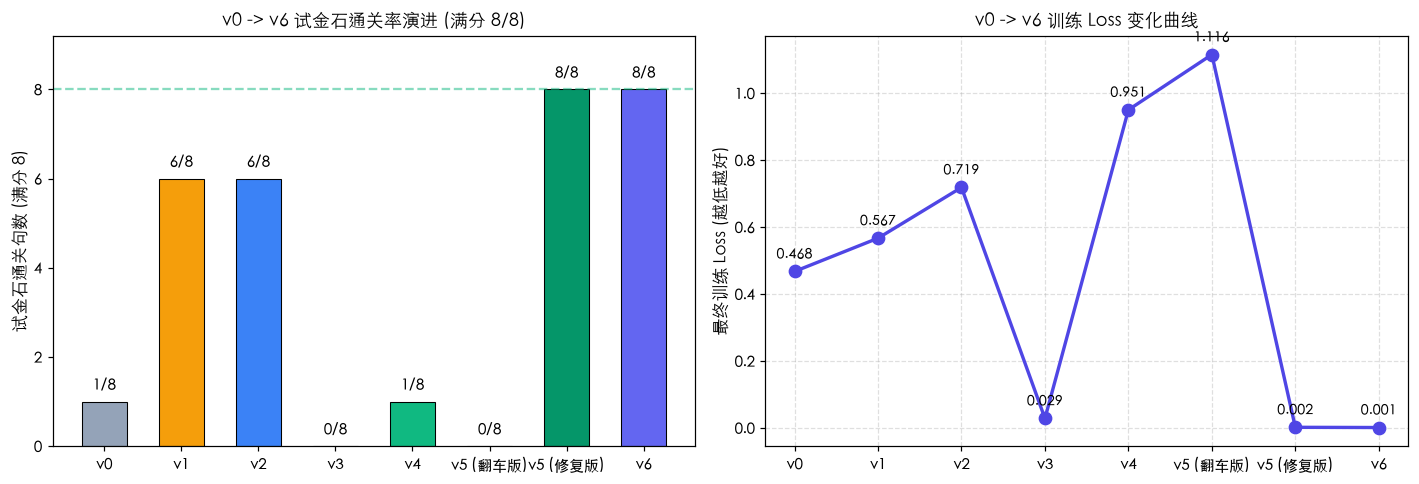

In [15]:
import platform
import glob
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

# 自动配置中文字体（兼容 macOS / Linux / Windows）
font_candidates = [
    '/System/Library/Fonts/PingFang.ttc',
    '/System/Library/Fonts/STHeiti Light.ttc',
    '/System/Library/Fonts/Supplemental/Arial Unicode.ttf',
    '/usr/share/fonts/**/NotoSansCJK*.ttc',
    '/usr/share/fonts/**/NotoSansCJK*.otf',
]
zh_font = None
for pattern in font_candidates:
    matches = glob.glob(pattern, recursive=True)
    if matches:
        zh_font = fm.FontProperties(fname=matches[0])
        fm.fontManager.addfont(matches[0])
        plt.rcParams['font.sans-serif'] = [zh_font.get_name(), 'sans-serif']
        break
plt.rcParams['axes.unicode_minus'] = False

# ================= 图 1：v0 -> v6 进化成绩单 =================
labels = [h[0].split(":")[0] for h in history_board]
full_names = [h[0] for h in history_board]
losses = [h[1] for h in history_board]
scores = [h[2] for h in history_board]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), dpi=110)
colors = ['#94a3b8', '#f59e0b', '#3b82f6', '#ef4444', '#10b981', '#dc2626', '#059669', '#6366f1']

bars = ax1.bar(labels, scores, color=colors[:len(labels)], width=0.58, edgecolor='black', linewidth=0.7)
ax1.set_ylim(0, 9.2)
ax1.set_ylabel("试金石通关句数 (满分 8)", fontproperties=zh_font, fontsize=11)
ax1.set_title("v0 -> v6 试金石通关率演进 (满分 8/8)", fontproperties=zh_font, fontsize=12)
ax1.axhline(8, color='#10b981', linestyle='--', alpha=0.5)
for bar, sc in zip(bars, scores):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2, f"{sc}/8",
             ha='center', va='bottom', fontsize=10)

ax2.plot(labels, losses, marker='o', linewidth=2.2, color='#4f46e5', markersize=8)
ax2.set_ylabel("最终训练 Loss (越低越好)", fontproperties=zh_font, fontsize=11)
ax2.set_title("v0 -> v6 训练 Loss 变化曲线", fontproperties=zh_font, fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.4)
for i, l_val in enumerate(losses):
    ax2.annotate(f"{l_val:.3f}", (labels[i], losses[i]), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

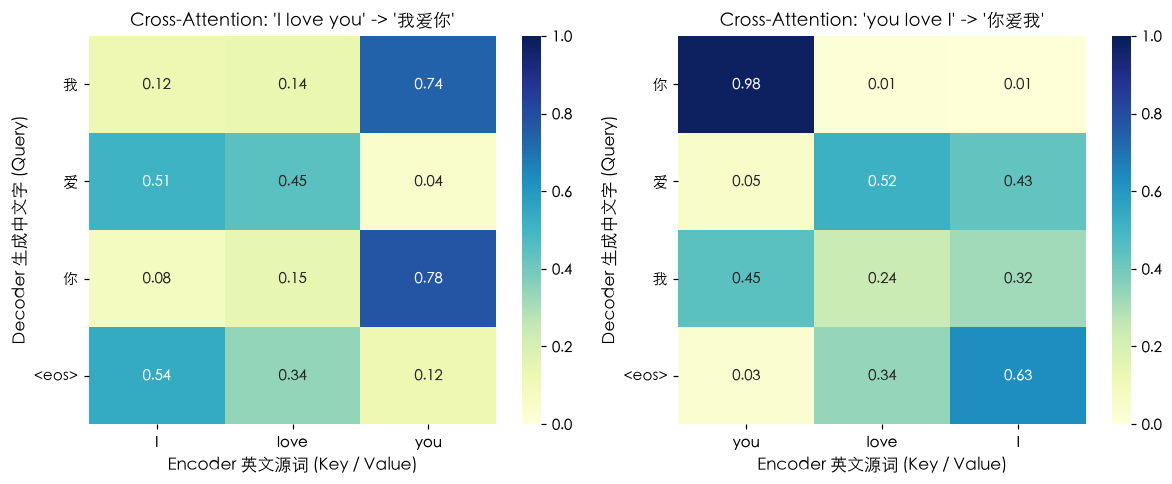

In [16]:
# ================= 图 2：Cross-Attention 跨语言注意力对齐热力图 =================
# 对比 "I love you" -> "我爱你" 与 "you love I" -> "你爱我" 的交叉注意力矩阵
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), dpi=110)

for ax, (src_text, tgt_text) in zip(axes, [("I love you", "我爱你"), ("you love I", "你爱我")]):
    _ = translate_v6(src_text)  # 触发一次前向推演，记录注意力矩阵
    # 取出最后一层 Decoder 的 Cross-Attention 在 4 个头上的平均权重
    # 形状: (Tgt_len, Src_len)，对应生成每个中文字 + <eos> 时对英文词的关注度
    attn_matrix = model_v6.decoder[-1].cross_attn.last_attn[0].mean(dim=0).cpu().numpy()
    src_tokens = src_text.split()
    tgt_tokens = list(tgt_text) + ["<eos>"]

    sns.heatmap(
        attn_matrix[:len(tgt_tokens), :len(src_tokens)],
        annot=True, fmt=".2f", cmap="YlGnBu", cbar=True, ax=ax,
        xticklabels=src_tokens, yticklabels=tgt_tokens, vmin=0.0, vmax=1.0
    )
    ax.set_xlabel("Encoder 英文源词 (Key / Value)", fontproperties=zh_font, fontsize=11)
    ax.set_ylabel("Decoder 生成中文字 (Query)", fontproperties=zh_font, fontsize=11)
    ax.set_title(f"Cross-Attention: '{src_text}' -> '{tgt_text}'", fontproperties=zh_font, fontsize=12)
    for label in ax.get_yticklabels():
        if zh_font:
            label.set_fontproperties(zh_font)
        label.set_rotation(0)

plt.tight_layout()
plt.show()

---
## 🎓 结语：回看我们亲手走过的「发明者之路」

如果一开始就给你扔出 `ModelV6_Transformer` 那上百行代码，你一定会觉得各个组件繁琐又突兀：
* 为什么要加一串奇怪的 $\sin / \cos$？
* 为什么要拆出 $Q, K, V$ 还要除以 $\sqrt{d_k}$？
* 为什么要搞出 `Subsequent Mask` 和 `Padding Mask` 两个掩码？
* 为什么每个子层外面都要包一层 `x + SubLayer(x)` 和 `LayerNorm`，后面还得跟一个 `FFN`？

但当你顺着 **`v0 -> v6` 踩坑修 Bug** 走完一遍后，每一个组件的存在都有了不可替代的理由：

1. **没有前缀汇总（`v0`）** $\implies$ 模型只看得见当前最后 1 个词，所有句子都翻译成同一句话；
2. **只有词袋平均、没有位置编码（`v1`）** $\implies$ 向量加法满足交换律，`"I love you"` 和 `"you love I"` 在模型眼里完全等价；
3. **有了位置编码、但只有死板平均（`v2`）** $\implies$ 所有历史词平分 $\frac{1}{t}$ 权重，长句关键信息被稀释成一锅粥；
4. **有了多头注意力、但没有因果掩码（`v3`）** $\implies$ 训练时直接往右偷看下一时刻的标准答案，平时训练满分、一上推理考场 `0/8`；
5. **有了掩码注意力、但直接往深了堆 6 层（`v5 翻车版`）** $\implies$ 梯度在层层矩阵乘法中消失、特征坍缩，6 层模型退化成只会喊 `"我我我我..."` 的复读机；加上 **残差连接 + LayerNorm + FFN（`v5 修复版`）** 才打通梯度高速公路，建成完整的 **GPT 式架构**；
6. **把单序列拆成双向 Encoder + 交叉注意力 Decoder（`v6`）** $\implies$ 让英文源句摆脱下三角掩码的束缚、实现双向全局理解，并通过 Cross-Attention 实现中英文精准对齐。

> **先完成，再完善。** 希望这种「从 10 行残次品出发、被问题推着向前走」的视角，能让你真正体会到创造深度学习架构的乐趣！